# Hafta 12 · Doğal Dil İşleme ve Dil Modelleri

**Yapay Zekâya Giriş — Laboratuvar Defteri**  
Dr. Seda Bayat Toksöz · Iğdır Üniversitesi · 2026–2027 Güz

Bu defterde metnin bilgisayarda nasıl saklandığını görecek, BPE tokenizasyonunu sıfırdan yazacak, TF-IDF ile duygu analizi yapacak ve dört proje gerçekleştireceksiniz: (P4) ders notlarımızda BPE öğrenmek, (P2) skip-gram ile kendi kelime gömmelerimizi eğitmek, (P1) karakter düzeyinde n-gram metin üretici, (P3) karakter düzeyinde LSTM dil modeli. Projelerin hepsi aşağıdaki 0. bölümde gömülü olan ders notları derlemiyle çalışır; internet gerekmez.

Hücreleri yukarıdan aşağıya sırayla çalıştırın (**Shift + Enter**). Parametreleri değiştirip sonucun nasıl değiştiğini gözlemleyin.

In [1]:
# Grafik ayarları (ders notlarıyla aynı renk paleti)
import matplotlib.pyplot as plt
plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.prop_cycle": plt.cycler(color=["#0072B2", "#D55E00", "#009E73", "#E69F00", "#56B4E9", "#CC79A7"]),
})

## 1. Bilgisayar metni nasıl görür? Unicode ve UTF-8
Her karakterin bir **kod noktası** (numarası) vardır; dosyada ve bellekte bu numara **baytlara** çevrilerek saklanır.

In [2]:
for k in ["A", "ç", "ğ", "ı", "İ", "€"]:
    b = k.encode("utf-8")              # karakter → baytlar
    print(f"{k}  U+{ord(k):04X}  → {len(b)} bayt: {list(b)}")

s = "Iğdır"
print(f"\n{s}: {len(s)} karakter, {len(s.encode())} bayt")
kucuk = "İ".lower()                    # Python'un varsayılanı
print("İ →", kucuk, "→", len(kucuk), "kod noktası:",
      [f"U+{ord(c):04X}" for c in kucuk])

A  U+0041  → 1 bayt: [65]
ç  U+00E7  → 2 bayt: [195, 167]
ğ  U+011F  → 2 bayt: [196, 159]
ı  U+0131  → 2 bayt: [196, 177]
İ  U+0130  → 2 bayt: [196, 176]
€  U+20AC  → 3 bayt: [226, 130, 172]

Iğdır: 5 karakter, 7 bayt
İ → i̇ → 2 kod noktası: ['U+0069', 'U+0307']


## 2. Ön işleme: Türkçede küçük harf tuzağı
Python'un `lower()` fonksiyonu Türkçe I/ı ve İ/i kuralını bilmez.

In [3]:
import re
metin = "IŞIK Festivali İSTANBUL'da! Kargo GEÇ geldi ama ürün çok güzel."
print(metin.lower())                     # Python varsayılanı (hatalı)

tr = str.maketrans({"I": "ı", "İ": "i"})  # önce Türkçe kural
kucuk = metin.translate(tr).lower()
print(kucuk)

tokenlar = re.findall(r"\w+", kucuk)    # noktalamayı at, böl
print(tokenlar)
durak = {"ama", "ve", "bir", "çok"}      # durak kelimeler
print([t for t in tokenlar if t not in durak])

işik festivali i̇stanbul'da! kargo geç geldi ama ürün çok güzel.
ışık festivali istanbul'da! kargo geç geldi ama ürün çok güzel.
['ışık', 'festivali', 'istanbul', 'da', 'kargo', 'geç', 'geldi', 'ama', 'ürün', 'çok', 'güzel']
['ışık', 'festivali', 'istanbul', 'da', 'kargo', 'geç', 'geldi', 'ürün', 'güzel']


## 3. BPE'yi sıfırdan yazmak (Çözümlü Örnek 12.1)
En sık yan yana gelen sembol çiftini birleştir, tekrarla.

In [4]:
from collections import Counter
derlem = {"ev": 6, "evler": 4, "evde": 2, "derler": 2, "geldi": 1}
kelimeler = {tuple(k): s for k, s in derlem.items()}  # karakterler
def birlestir(sem, cift):                 # çifti tek sembole çevir
    yeni, i = [], 0
    while i < len(sem):
        if tuple(sem[i:i + 2]) == cift:
            yeni.append(sem[i] + sem[i + 1]); i += 2
        else:
            yeni.append(sem[i]); i += 1
    return tuple(yeni)
kurallar = []
for adim in range(1, 4):
    say = Counter()                       # ağırlıklı çift sayımı
    for sem, s in kelimeler.items():
        for cift in zip(sem, sem[1:]): say[cift] += s
    cift, n = say.most_common(1)[0]       # en sık çift
    kurallar.append(cift)
    kelimeler = {birlestir(k, cift): s for k, s in kelimeler.items()}
    print(f"{adim}: {cift} → {''.join(cift)} ({n})")

1: ('e', 'v') → ev (12)
2: ('e', 'r') → er (8)
3: ('l', 'er') → ler (6)


### Öğrenilen kuralları yeni kelimelere uygulamak

In [5]:
def tokenize(kelime):
    sem = tuple(kelime)                   # önce karakterler
    for cift in kurallar:                 # kurallar öğrenildiği sırayla
        sem = birlestir(sem, cift)
    return list(sem)

for k in ["evlerde", "evler", "derler", "gelirler"]:
    print(f"{k:9s} →", tokenize(k))

evlerde   → ['ev', 'ler', 'd', 'e']
evler     → ['ev', 'ler']
derler    → ['d', 'er', 'ler']
gelirler  → ['g', 'e', 'l', 'i', 'r', 'ler']


## 0. Proje derlemi: ders notlarımız
Aşağıdaki hücre, bu dersin notlarından alınmış yaklaşık 40 bin karakterlik düzyazıyı `DERLEM` değişkenine yükler. Dört projenin hepsi bu metni kullanır. Kendi metninizi (ör. bir roman, haberler) koyup sonuçları karşılaştırabilirsiniz.

In [6]:
DERLEM = r"""Bu dersteki amacımız formül ezberlemek değil, bir modelin neden ve nasıl çalıştığını anlamaktır. Bu yüzden her haftada adım adım çözülmüş sayısal örnekler bulacaksınız. Bu örnekleri yalnızca okumayın; kâğıt, kalem ve hesap makinesiyle kendiniz de çözün. Sınavlardaki hesaplama soruları bu örneklerin benzerleridir. Haftaların içindeki kısa Python kodları ise laboratuvar uygulamalarına hazırlık niteliğindedir; kodları kendi bilgisayarınızda ya da Google Colab üzerinde çalıştırarak sonuçları notlardaki elle yapılmış hesaplarla karşılaştırmanız, konuyu pekiştirmenin en iyi yoludur.
Her hafta aynı yapıyı izler. Haftanın başında o haftanın kazanımları ve anahtar kavramları listelenir; ardından konu anlatımı, şekiller ve çözümlü örnekler gelir. Hafta, kısa bir özet ve değerlendirme soruları ile biter. Sorular üç gruptur: (A) çoktan seçmeli sorular, (B) kısa cevaplı ve hesaplama soruları, (C) birden çok kavramı birleştiren ileri düzey sorular. Soruların cevapları Ek D'deki cevap anahtarında yer alır; önce kendiniz çözmeye çalışın, sonra kontrol edin. Metin içinde farklı amaçlara hizmet eden renkli kutular kullanılmıştır:
Yuvarlama: Ara adımlarda genellikle 3-4 anlamlı basamak tutulmuştur. Sınavda kendi yuvarlamanızdan kaynaklanan küçük farklar sorun değildir. Terimler: Türkçe terimlerin İngilizce karşılıkları ilk geçtikleri yerde parantez içinde verilmiştir. Tüm terimler Ek C'deki sözlükte alfabetik olarak toplanmıştır. Görseller: Fotoğraf örnekleri, açık kaynaklı scikit-image kütüphanesinin örnek görüntülerinden alınmıştır. Diğer tüm şekil ve grafikler bu notlar için hazırlanmıştır.
zekâ problemini doğru öğrenme türüyle eşleştirebilmesi, temel modelleri elle ve kodla uygulayabilmesi ve modellerin başarımını doğru metriklerle yorumlayabilmesi hedeflenir.
Yapay zekâ (artificial intelligence, AI), normalde insan zekâsı gerektiren görevleri -algılama, öğrenme, akıl yürütme, problem çözme, karar verme ve dil anlama gibi- yerine getirebilen bilgisayar sistemleri geliştirmeyi amaçlayan bilim ve mühendislik dalıdır.
Alan Turing, 1950 yılında yayımladığı "Computing Machinery and Intelligence" makalesinde "Makineler düşünebilir mi?" sorusunun belirsiz olduğunu savunarak yerine ölçülebilir bir deney önermiştir: taklit oyunu (imitation game). Bugün Turing testi (Turing test) olarak bilinen bu deneyde bir sorgulayıcı, göremediği iki tarafla yalnızca yazılı mesajlarla konuşur (Şekil 1.1). Taraflardan biri insan, diğeri makinedir. Sorgulayıcı hangisinin makine olduğunu güvenilir biçimde ayırt edemiyorsa makine testi geçmiş sayılır.
Yapay zekâ sistemleri yeteneklerinin genişliğine göre üç düzeyde incelenir (Tablo 1.2). Günümüzde kullanılan sistemlerin büyük çoğunluğu belirli bir görev için tasarlanmış dar yapay zekâ (narrow AI) örnekleridir. Büyük dil modelleri çok sayıda farklı görevi yerine getirebildikleri için "genel amaçlı" olarak nitelendirilse de insan düzeyinde genel yapay zekâya (artificial general intelligence, AGI) ulaşılıp ulaşılmadığı hâlâ tartışma konusudur.
Tom Mitchell (1997) daha biçimsel ve sınavlarda sıkça sorulan bir tanım vermiştir: Bir bilgisayar programı, T görevlerindeki P ölçütüyle ölçülen başarımı E deneyimiyle artıyorsa, bu program E deneyiminden öğreniyor denir. Burada T görev (task), P performans ölçütü (performance), E ise deneyimdir
Bu farkı bir istenmeyen e-posta (spam) filtresi üzerinden düşünelim. Kural tabanlı bir filtre "konu satırında kazandınız geçiyorsa spam olarak işaretle" gibi yüzlerce kural içerir. Bu yaklaşımın üç temel sorunu vardır: (i) kurallar zamanla çoğalır ve bakımı zorlaşır, (ii) spam gönderenler kelimeleri değiştirerek ("kazndınız") kuralları kolayca atlatır, (iii) her dil ve her yeni saldırı türü için kural yazmak gerekir. Makine öğrenmesi tabanlı bir filtre ise kullanıcıların "spam" olarak işaretlediği binlerce e-postadan hangi kelime ve özelliklerin spam ile ilişkili olduğunu kendisi öğrenir ve yeni örnekler geldikçe yeniden eğitilerek güncellenir.
Klasik makine öğrenmesi ile derin öğrenme arasındaki en önemli fark, öznitelik (feature) adı verilen ve modele girdi olarak verilen ölçülebilir özelliklerin nasıl elde edildiğidir. Klasik yaklaşımda uzman bir insan, örneğin bir görüntüden kenar yoğunluğu, renk histogramı veya doku ölçüleri gibi öznitelikleri elle tasarlar (öznitelik mühendisliği (feature engineering)). Derin öğrenmede ise ağ, ham pikselleri girdi olarak alır ve hangi özniteliklerin önemli olduğunu eğitim sırasında kendisi öğrenir
Yapay zekânın tarihi düz bir çizgide ilerlememiş; büyük beklentilerle geçen "bahar" dönemleri ile hayal kırıklığı ve fon kesintileriyle geçen YZ kışları (AI winters) birbirini izlemiştir. Şekil 1.5 başlıca kilometre taşlarını özetlemektedir. Tarihçeden çıkarılacak en önemli ders şudur: Derin öğrenmenin 2012'den sonraki yükselişi tek bir buluşa değil, üç etkenin aynı anda olgunlaşmasına dayanır.
2024 Nobel Fizik Ödülü, yapay sinir ağlarıyla makine öğrenmesini mümkün kılan temel keşifleri nedeniyle John Hopfield ve Geoffrey Hinton'a verildi. Aynı yıl Nobel Kimya Ödülü'nün yarısı protein yapısı tahmini yapan AlphaFold modeli için Demis Hassabis ve John Jumper'a, diğer yarısı ise hesaplamalı protein tasarımı için David Baker'a verildi. Yapay zekâ böylece temel bilimlerin en prestijli ödüllerine konu oldu.
Ajanın çalıştığı ortamın özellikleri tasarım zorluğunu belirler. Ortam tam gözlemlenebilir (satranç tahtasının tamamı görünür) ya da kısmi gözlemlenebilir (taksi, köşenin arkasını göremez); deterministik (aynı hamle hep aynı sonucu verir) ya da stokastik (yayanın ne yapacağı kesin değildir); statik ya da dinamik olabilir. Otonom sürüş; kısmi gözlemlenebilir, stokastik ve dinamik bir ortam olduğu için en zor yapay zekâ problemlerinden biridir.
değeri en küçük olan durumu genişletir. Sezgisel fonksiyon gerçek kalan maliyeti hiçbir zaman aşmıyorsa (kabul edilebilir sezgisel), A en düşük maliyetli çözümü bulmayı garanti eder.
dönüşür ve aynı sonucu genellikle daha fazla düğüm genişleterek bulur (bu küçük haritada her iki yöntem de beş düğümün tamamını genişletir; fark büyük haritalarda ortaya çıkar).
Yapay zekâ bugün hemen her sektörde kullanılmaktadır. Şekil 1.7 bu dönem boyunca inceleyeceğimiz yöntemlerin gerçek hayattaki karşılıklarından bazılarını göstermektedir.
Yanlılık ve adalet: Model, eğitim verisindeki önyargıları öğrenir ve büyütebilir. Örneğin geçmişte çoğunlukla erkek adayların işe alındığı bir şirketin verileriyle eğitilen bir özgeçmiş değerlendirme sistemi, kadın adayları sistematik olarak düşük puanlayabilir. Bu duruma algoritmik yanlılık (algorithmic bias) denir. Gizlilik ve veri koruma: Kişisel verilerin toplanması, saklanması ve işlenmesi yasal düzenlemelere uygun olmalıdır. Türkiye'de bu konuda 6698 sayılı Kişisel Verilerin Korunması Kanunu
"Çöp girer, çöp çıkar" (garbage in, garbage out) ilkesi yapay zekâda da geçerlidir. Hatalı, eksik veya yanlı verilerle eğitilen bir model, ne kadar karmaşık olursa olsun güvenilir sonuçlar
(a) şıkkındaki işlem, 6. haftada göreceğimiz yapay nöronun yaptığı hesabın ta kendisidir: girdileri ağırlıklarıyla çarp, topla ve bias ekle. (c) şıkkı ise aynı anda iki nöronun hesabını yapar.
12. Mitchell'in T-P-E tanımını, bir e-ticaret sitesinde kullanıcılara ürün öneren bir sistem için yazınız. Bu sistemin başarımını yalnızca "tıklama oranı" ile ölçmenin hangi etik ve teknik sorunlara yol açabileceğini tartışınız.
Makine öğrenmesi modelleri kurallarını veriden çıkardığı için verinin yapısını doğru anlamak her şeyin başlangıcıdır. Tablo biçimindeki bir veri setinde (dataset) her satır bir örnek (sample, instance) (gözlem), her sütun bir öznitelik ve tahmin etmek istediğimiz sütun ise etiket (label) ya da hedef
Denetimsiz öğrenmede (unsupervised learning) verilerin etiketi yoktur. Model, verinin içindeki yapıyı, grupları veya örüntüleri kendi başına keşfetmeye çalışır.
Pekiştirmeli öğrenmede (reinforcement learning) bir ajan, çevresiyle deneme-yanılma yoluyla etkileşime girer. Her eyleminin ardından bir ödül (reward) (ya da ceza) alır ve uzun vadede toplam ödülü en üst düzeye çıkaran davranış stratejisini (policy) öğrenir.
Etiketleme çoğu zaman pahalıdır: Bir radyoloğun binlerce MR görüntüsünü tek tek işaretlemesi haftalar sürer. Yarı denetimli öğrenme (semi-supervised learning), az sayıda etiketli örneği çok sayıda etiketsiz örnekle birlikte kullanır. Öz-denetimli öğrenmede (self-supervised learning) ise etiket verinin kendisinden üretilir. Örneğin bir cümlenin sonraki kelimesini tahmin etmek için etikete gerek yoktur, çünkü sonraki kelime metnin içinde zaten vardır. Büyük dil modellerinin ön eğitimi tam
5. Model eğitimi: Uygun algoritma seçilir ve eğitim verisiyle eğitilir. 6. Değerlendirme: Model, eğitimde hiç görmediği test verisi üzerinde uygun metriklerle ölçülür
Sektörde yapılan anketlerde veri bilimcilerin zamanlarının önemli bir bölümünü model geliştirmeye değil, veriyi toplamaya, temizlemeye ve düzenlemeye harcadıkları sıkça dile getirilir. Gerçek projelerde en çok emek isteyen adım genellikle veridir.
Eğitim kümesi (training set): Modelin parametrelerini öğrenmek için kullanılır. Doğrulama kümesi (validation set): Model seçimi ve hiperparametre ayarı (ör. polinom derecesi, öğrenme oranı) için kullanılır. Test kümesi (test set): Yalnızca en sonda, nihai başarımı raporlamak için bir kez kullanılır.
Bir model eğitim verisindeki gürültüyü ve rastlantısal ayrıntıları da ezberlerse eğitim verisinde çok başarılı, yeni verilerde ise başarısız olur. Bu duruma aşırı öğrenme (overfitting) denir. Tersine, model verideki ilişkiyi yakalayamayacak kadar basitse hem eğitim hem test verisinde başarısız olur; buna
Aşırı öğrenmeyle mücadele yöntemlerini (düzenlileştirme, çapraz doğrulama) 5. haftada, derin ağlara özgü yöntemleri (dropout, veri artırma) 7. ve 10. haftalarda ayrıntılı olarak inceleyeceğiz.
arasında değişir. Uzaklık hesabına dayanan yöntemlerde (k-NN, k-means) ve gradyan inişle eğitilen modellerde büyük ölçekli öznitelik baskın hâle gelir. Bu nedenle öznitelikler benzer aralıklara
veriler için doğru yöntem one-hot kodlamadır (one-hot encoding): Her kategori için ayrı bir sütun açılır ve yalnızca ilgili sütun 1, diğerleri 0 olur.
Sınıflandırma problemlerinde sınıfların örnek sayıları çoğu zaman çok farklıdır: Kredi kartı işlemlerinin binde biri sahtedir, tıbbi taramaların küçük bir kısmı hastalık içerir. Bu tür dengesiz veri (imbalanced data) setlerinde model, çoğunluk sınıfını tahmin ederek yüksek doğruluğa ulaşabilir ve azınlık sınıfını hiç öğrenmeyebilir. Başlıca çözümler:
Yüzlerce özniteliği olan bir veri setinde öznitelikler çoğu zaman birbirine bağımlıdır ve veri aslında daha düşük boyutlu bir yapıda yaşar. Temel bileşen analizi (principal component analysis, PCA), veriyi varyansın en büyük olduğu yönlere (temel bileşenlere) izdüşürür: İlk bileşen verinin en çok yayıldığı doğrultudur, ikinci bileşen ona dik ve kalan varyansı en çok açıklayan doğrultudur; bu böyle devam eder. Bileşenler, standartlaştırılmış verinin kovaryans matrisinin özvektörleridir; her bileşenin açıkladığı varyans oranı ilgili özdeğerle orantılıdır. Uygulamada ilk k bileşen alınarak (ör. toplam varyansın %95'ini açıklayan sayıda) veri d boyuttan k boyuta indirgenir. PCA; görselleştirme (2-3 boyuta indirgeme), gürültü azaltma ve uzaklık tabanlı yöntemleri hızlandırma amacıyla kullanılır. Doğrusal olmayan yapılar için t-SNE ve UMAP gibi görselleştirme yöntemleri tercih edilir.
Dengesiz veride yeniden örnekleme (yalnızca eğitim kümesinde), sınıf ağırlıkları ve doğruluk dışı metrikler kullanılır. PCA, veriyi en çok varyans taşıyan yönlere izdüşürerek boyut
Regresyon, sürekli bir hedef değişkeni tahmin etmeyi amaçlayan denetimli öğrenme görevidir. Bu ailenin en basit ve en çok kullanılan üyesi doğrusal regresyondur (linear regression). Tek öznitelikli durumda model bir doğrudur:
bir parabol çizse de w1 , w2 , b parametrelerine göre doğrusal olduğu için yine doğrusal regresyonla çözülür. Buna polinom regresyon (polynomial regression) denir; 2. haftadaki Şekil 2.6 bu
Ayrıca kare fonksiyonunun türevi kolay alındığından optimizasyon kolaylaşır. Alternatif olarak hataların mutlak değerinin ortalaması (MAE) da kullanılabilir (Şekil 3.2).
Formül sezgisel olarak şunu söyler: x ortalamanın üzerindeyken y de ortalamanın üzerinde olma eğilimindeyse pay pozitif çıkar ve eğim pozitif olur. b'nin formülü ise en iyi doğrunun her zaman
ortalamayı tahmin etmekten bile kötüyse (SSE SST) R2 negatif çıkar. Negatif R2 , modelin işe yaramadığının güçlü bir işaretidir. Ayrıca yüksek R2 tek başına modelin doğru olduğunu kanıtlamaz; artıkların grafiğine de bakılmalıdır.
Yoğun siste bir dağın tepesinde olduğunuzu ve vadiye inmek istediğinizi düşünün. Etrafı göremiyorsunuz; ancak ayağınızın altındaki zeminin hangi yöne doğru eğimli olduğunu hissedebiliyorsunuz. Mantıklı strateji, en dik iniş yönünde küçük bir adım atmak ve bunu tekrarlamaktır. Gradyan iniş tam olarak budur: Dağ kayıp fonksiyonu, konumunuz parametreler, eğim gradyan, adım uzunluğunuz ise öğrenme oranıdır.
Öğrenme oranı, eğitimin başarısını belirleyen en önemli hiperparametredir (hyperparameter). Hiperparametre, modelin veriden öğrendiği bir değer değil, eğitimden önce bizim belirlediğimiz bir ayardır. Şekil 3.3 aynı fonksiyonda üç farklı öğrenme oranının davranışını göstermektedir.
Öznitelikler farklı ölçeklerdeyse kayıp yüzeyi bir yönde dik, diğer yönde düz uzamış bir vadiye dönüşür. Gradyan dik yönde büyük olduğu için adımlar vadinin duvarları arasında zikzak çizer; öğrenme oranı dik yöne göre küçük seçilmek zorunda kalır ve düz yönde ilerleme çok yavaşlar.
Yığın (batch) gradyan iniş: Her adımda tüm eğitim verisi kullanılır. Kararlıdır ancak büyük veride her adım çok pahalıdır. Stokastik gradyan iniş (stochastic gradient descent, SGD): Her adımda rastgele seçilen tek örnek kullanılır. Adımlar ucuz ama gürültülüdür.
10. Öğrenme oranının çok küçük ve çok büyük seçilmesinin sonuçlarını birer cümleyle açıklayınız. Öğrenme oranı neden "parametre" değil "hiperparametre" olarak adlandırılır?
Sınıflandırmada amaç, bir örneği önceden tanımlı sınıflardan birine (ya da birkaçına) atamaktır. Model, öznitelik uzayını sınıflara karşılık gelen bölgelere ayırır; bu bölgeleri ayıran yüzeye karar sınırı (decision boundary) denir. Sınıflandırma problemleri üç türe ayrılır:
lenmiştir. (a) Haftada 3 saat ve 5 saat çalışan öğrencilerin geçme olasılıklarını hesaplayınız ve 0.5 eşiğine göre sınıflandırınız. (b) Karar sınırını bulunuz.
Yani güncelleme miktarı, tahmin edilen olasılık ile gerçek etiket arasındaki farkla orantılıdır. Model gradyan inişle (3. hafta) eğitilir. İkiden fazla sınıf olduğunda sigmoid yerine softmax fonksiyonu kullanılır; bunu 7. haftada göreceğiz.
k-en yakın komşu (k-nearest neighbors, k-NN) algoritması, "bana arkadaşını söyle, sana kim olduğunu söyleyeyim" ilkesine dayanır. Yeni bir örneği sınıflandırmak için eğitim kümesinde ona en yakın k örnek bulunur ve bu komşular arasında en çok görülen sınıf (çoğunluk oylaması) tahmin edilir. Regresyonda ise komşuların hedef değerlerinin ortalaması alınır.
karar sınırı girintili çıkıntılı olur ve aşırı öğrenme görülür. Büyük k ise karar sınırını aşırı yumuşatır ve küçük sınıfları "yutar" (eksik öğrenme). Uygun k değeri doğrulama kümesi veya çapraz doğrulama (5. hafta) ile seçilir. İki sınıflı problemlerde oyların eşit çıkmaması için k genellikle tek sayı
Sonuç: IG(Devam) IG(Ödev) olduğundan kök düğümde Devam özniteliği kullanılır. Aynı işlem alt düğümlerde tekrarlanarak Şekil 4.4'deki ağaç elde edilir. (Gini ile de aynı sonuç çıkar:
İki sınıfı ayıran sonsuz sayıda doğru çizilebilir. Destek vektör makineleri (support vector machines, SVM), bu doğrular arasından iki sınıfa da en uzak olanı, yani sınıflar arasındaki boşluğu (marj (margin)) en büyük yapanı seçer (Şekil 4.6). Karar sınırına en yakın olan ve sınırın konumunu belirleyen örneklere destek vektörleri (support vectors) denir; diğer örnekler silinse bile karar sınırı değişmez. Geniş marj, yeni örneklerde daha iyi genelleme sağlar.
10. Bir düğümde 9 "Evet" ve 5 "Hayır" örneği vardır. Bir öznitelikle bölündüğünde birinci çocukta 6 Evet-2 Hayır, ikinci çocukta 3 Evet-3 Hayır oluşmaktadır. (a) Ebeveyn düğümün entropisini, (b) bu bölmenin bilgi kazancını hesaplayınız.
yazınız, (b) her aday için ağırlıklı Gini safsızlığını hesaplayıp en iyi eşiği seçiniz, (c) tek bir eşikle tüm örneklerin neden doğru sınıflandırılamayacağını açıklayınız.
Bir sınıflandırıcının başarısını ölçmenin akla gelen ilk yolu, doğru tahminlerin oranı olan doğruluktur (accuracy). Ancak doğruluk tek başına yanıltıcı olabilir. Bin kişide 50'sinin hasta olduğu bir tarama programı düşünün. Hiçbir şey öğrenmeden herkese "sağlıklı" diyen bir model %95 doğruluk elde eder; ama tek bir hastayı bile yakalayamaz. Sınıfların sayıca çok farklı olduğu bu tür veri setlerine dengesiz veri seti (imbalanced dataset) denir ve gerçek hayattaki problemlerin çoğu (hastalık teşhisi, dolandırıcılık, arıza tespiti) bu türdendir. Bu nedenle sınıflandırıcıları farklı açılardan ölçen metriklere ihtiyaç vardır.
Kesinlik (precision) ve duyarlılık (recall, sensitivity) birbirini tamamlayan iki sorunun cevabıdır. Duyarlılık tıpta "hassasiyet" (sensitivity) veya "doğru pozitif oranı" (TPR) olarak da bilinir. F1 skoru (F1 score), iki metriği tek sayıda birleştirir. Harmonik ortalama kullanıldığı için metriklerden biri çok düşükse F1 de düşük çıkar; böylece "yalnızca birinde iyi" olan model ödüllendirilmez.
minleri gösterir ve köşegen doğru tahminleri içerir. Kesinlik, duyarlılık ve F1 her sınıf için "o sınıf pozitif, diğerleri negatif" kabul edilerek ayrı ayrı hesaplanır. Sonra bu değerlerin basit ortalaması alınır (makro ortalama (macro average)) ya da sınıfların örnek sayısına göre ağırlıklı ortalaması alınır (ağırlıklı ortalama). Makro ortalama, küçük sınıflara da büyük sınıflar kadar önem verdiği için dengesiz veride tercih edilir.
Rastgele bir modelin AP'si pozitif sınıfın oranına eşittir (%1 pozitif içeren veride 0.01); bu yüzden AP, aynı verideki AUC'den çok daha sert bir ölçüttür.
Veriyi bir kez eğitim ve doğrulama kümelerine ayırmak, özellikle küçük veri setlerinde şansa bağlı sonuçlar verebilir: Doğrulama kümesine kolay örnekler düşerse model olduğundan iyi görünür. k-katlı çapraz doğrulama (k-fold cross-validation) bu sorunu şöyle çözer (Şekil 5.4): Eğitim verisi k eşit parçaya (kata) bölünür. Model k kez eğitilir; her seferinde bir kat doğrulama, kalan k 1 kat eğitim için kullanılır. Sonuçta k başarım değerinin ortalaması ve standart sapması raporlanır. Yaygın
sayısı hızla patladığından rastgele arama, belirli bir bütçe kadar rastgele kombinasyon dener ve aynı bütçede genellikle ızgaradan daha iyi sonuç verir; çünkü önemsiz hiperparametrelere eşit zaman harcamaz. Önceki denemelerden öğrenerek umut vadeden bölgelere yönelen Bayesçi optimizasyon araçları (Optuna gibi) da yaygındır.
lanan hatadır (aşırı öğrenme). Model karmaşıklaştıkça yanlılık azalır, varyans artar. Amaç, toplam hatayı en küçük yapan dengeyi bulmaktır (Şekil 5.5).
Aşırı öğrenmeyi azaltmanın en etkili yollarından biri düzenlileştirmedir (regularization). Bu yaklaşımda kayıp fonksiyonuna büyük ağırlıkları cezalandıran bir terim eklenir:
Şimdi denetimsiz öğrenmenin en bilinen algoritmasına geçelim. k-ortalamalar (k-means) algoritması, etiketsiz veriyi önceden belirlenen k sayıda kümeye ayırır. Her küme bir merkez (centroid) ile temsil edilir ve her nokta en yakın merkezin kümesine atanır.
nedenle WCSS'yi en küçük yapan k aranmaz. Bunun yerine dirsek yönteminde (elbow method) WCSS, k'ye karşı çizilir ve eğrinin belirgin biçimde kırıldığı, sonrasında azalmanın yavaşladığı nokta seçilir (Şekil 5.8). Siluet skoru gibi başka ölçütler de kullanılabilir.
Kümeleme sonucunun kalitesini etiketsiz ölçmenin yaygın yolu siluet skorudur (silhouette score). Bir i örneği için ai kendi kümesindeki diğer örneklere ortalama uzaklık, bi ise en yakın başka kümenin örneklerine ortalama uzaklık olsun:
Dengesiz veride kesinlik-duyarlılık eğrisi ve AP, ROC/AUC'den daha bilgilendiricidir; AP, her doğru pozitif yakalandığındaki kesinliklerin ortalamasıdır. Hiperparametreler ızgara/rastgele aramayla ve çapraz doğrulamayla seçilir; test kümesi
İnsan beyninde yaklaşık 86 milyar sinir hücresi (nöron) bulunur ve her biri binlerce başka nöronla bağlantı kurar. Bir nöron, dendritleri aracılığıyla diğer nöronlardan elektrokimyasal sinyaller alır. Bu sinyaller hücre gövdesinde birikir; toplam uyarı belirli bir eşiği aşarsa nöron "ateşlenir" ve akson boyunca bir sinyal göndererek bağlantılı olduğu nöronları uyarır. Bağlantı noktalarına sinaps denir ve öğrenme, büyük ölçüde sinapsların güçlenmesi ya da zayıflamasıyla gerçekleşir. Yapay nöron (artificial neuron), bu davranışın çok basitleştirilmiş matematiksel bir modelidir (Şekil 6.1): Girdiler xi dendritlere, ağırlıklar (weights) wi sinaps güçlerine, toplama işlemi hücre gövdesine, aktivasyon fonksiyonu (activation function) f ise ateşleme eşiğine karşılık gelir:
Perceptronun sınıfları bir doğruyla ayırabilmesi için verinin doğrusal olarak ayrılabilir (linearly separable) olması gerekir. AND ve OR böyledir; ancak girdilerden yalnızca biri 1 olduğunda 1 üreten
Basamak fonksiyonunun türevi her yerde sıfırdır (sıfır noktasında ise tanımsızdır); bu nedenle gradyan inişle eğitim için kullanılamaz. Modern ağlarda türevlenebilir aktivasyon fonksiyonları
Nöronların katmanlar hâlinde düzenlendiği ve her katmanın bir sonrakine tam bağlı olduğu ağlara çok katmanlı perceptron (multilayer perceptron, MLP) ya da tam bağlı ileri beslemeli ağ (fully connected feedforward network) denir (Şekil 6.4). İlk katman girdi katmanı, son katman çıkış katmanı, aradakiler ise gizli katmanlardır (hidden layers). "Derin" öğrenmedeki derinlik, gizli katman sayısını ifade eder.
Tam bağlı bir katmanda ngirdi nöronlu bir katmandan nçıktı nöronlu bir katmana geçerken her çıkış nöronunun ngirdi ağırlığı ve bir bias değeri vardır:
malı normal dağılımdan çeker. Bias değerleri sıfırla başlatılır. Keras varsayılan olarak Glorot başlatmasını kullanır; PyTorch'un varsayılanı da aynı mertebede (1/ngirdi ölçeğinde) bir başlatmadır, He başlatması ise açıkça seçilir. Derin ağların 2010'lara kadar eğitilememesinin nedenlerinden biri bu basit ayarın bilinmemesiydi.
Gizli katmanlarda genellikle ReLU kullanılırken çıkış katmanının aktivasyonu ve kayıp fonksiyonu, problemin türüne göre seçilir (Tablo 6.2). Bu tablo, derin öğrenme modellerinin tasarımında en sık başvurulan kurallardan biridir.
olan bir dağılımdan çekilirse ön aktivasyon z'nin standart sapması yaklaşık kaç olur ve bu neden sorundur? (b) He başlatmasında ağırlıkların standart sapması ne olmalıdır? (c) Tüm ağırlıklar aynı sabit değerle başlatılırsa ne olur?
One-hot vektörde yalnızca doğru sınıfın elemanı 1 olduğundan toplamdan tek terim kalır: Kayıp, modelin doğru sınıfa verdiği olasılığın negatif logaritmasıdır. İki sınıflı durumda bu ifade 4. haftadaki ikili çapraz entropiye indirgenir.
Bir ağdaki milyonlarca parametrenin gradyanını tek tek elle türetmek imkânsızdır. Bunun yerine hesaplama, basit işlemlerden oluşan bir hesaplama grafiği (computational graph) olarak düşünülür ve türevler, analizdeki zincir kuralıyla (chain rule) grafiğin sonundan başına doğru aktarılır:
PyTorch, TensorFlow ve JAX gibi derin öğrenme kütüphaneleri, yukarıda elle yaptığımız işlemi otomatik türev (automatic differentiation) ile yapar: İleri geçiş sırasında hesaplama grafiğini kaydeder ve loss.backward() çağrıldığında tüm gradyanları hesaplar. Bu sayede araştırmacılar yalnızca modelin ileri geçişini yazar.
İki gözlem: (i) Adam'ın adımı gradyanın büyüklüğünden neredeyse bağımsızdır ve mertebesindedir; büyük gradyanlı parametrelerde adım otomatik olarak küçülür. (ii) Üçüncü adımda gradyan işaret değiştirdiği hâlde momentum sayesinde hareket aynı yönde, ama yavaşlayarak
Geri yayılımda gradyan, her katmandan geçerken o katmanın aktivasyon türeviyle ve ağırlıklarıyla çarpılır. Sigmoid fonksiyonunun türevi en fazla 0.25'tir (Şekil 7.4). On sigmoid katmanından geçen
Tüm ağırlıklar aynı değerle (ör. sıfırla) başlatılırsa bir katmandaki tüm nöronlar aynı çıktıyı üretir, aynı gradyanı alır ve aynı şekilde güncellenir. Nöronlar hiçbir zaman farklılaşamaz (simetri sorunu). Bu nedenle ağırlıklar küçük rastgele değerlerle başlatılır; bias değerleri ise sıfırla
Dropout (dropout), eğitim sırasında her iterasyonda nöronların rastgele bir kısmını (ör. %20-50) geçici olarak devre dışı bırakır (Şekil 7.5). Böylece ağ belirli nöronlara aşırı güvenemez ve bilgiyi daha dağıtık biçimde temsil etmeyi öğrenir. Bu, her adımda farklı bir alt ağ eğitmeye ve test sırasında bu alt ağların ortalamasını almaya benzer. Test sırasında dropout kapatılır ve tüm nöronlar kullanılır.
Momentum salınımları sönümler; Adam, momentum ile parametreye özgü adım büyüklüğünü birleştirir ve en yaygın optimizasyon algoritmasıdır. Sigmoid türevi en fazla 0.25 olduğundan derin sigmoid ağlarında gradyan sönümlenir; ReLU, iyi başlatma, toplu normalizasyon ve artık bağlantılar bu sorunu azaltır. Dropout, erken durdurma, ağırlık sönümü ve veri artırma derin ağlarda aşırı öğrenmeyi
RGB dışında, renk tonunu parlaklıktan ayıran HSV (ton, doygunluk, değer) gibi renk uzayları da vardır; örneğin "kırmızı nesneleri bul" gibi görevlerde HSV daha kullanışlıdır.
Bir görüntünün histogramı (histogram), her yoğunluk değerine sahip piksel sayısını gösteren grafiktir. Histogram görüntünün içeriği hakkında değil, ton dağılımı hakkında bilgi verir: Sola yığılmış histogram karanlık, sağa yığılmış aydınlık, dar bir aralığa sıkışmış histogram ise düşük kontrastlı bir görüntüyü gösterir. Histogram eşitleme (histogram equalization), yoğunluk değerlerini histogram tüm aralığa yayılacak şekilde yeniden dağıtarak kontrastı otomatik olarak artırır (Şekil 8.3). Tıbbi görüntülerde ve düşük ışıkta çekilmiş fotoğraflarda sıkça kullanılır. Histogram eşitleme, kümülatif histogramı dönüşüm fonksiyonu olarak kullanır. L gri seviyeli ve N piksellik bir görüntüde n j , j seviyesindeki piksel sayısı olmak üzere her k seviyesi şu yeni değere
Eşikleme, nesneyi arka plandan ayırmanın en basit yoludur ve 11. haftada göreceğimiz segmentasyonun en temel biçimidir. Eşiği elle seçmek zordur. Otsu yöntemi (Otsu's method), histogramı iki sınıfa (nesne ve arka plan) ayırırken sınıflar içi varyansı en küçük yapan eşiği otomatik olarak bulur (Şekil 8.4). Aydınlatmanın görüntü boyunca değiştiği durumlarda her bölge için ayrı eşik hesaplayan uyarlamalı eşikleme daha iyi sonuç verir.
Bu işlem, 9. haftada göreceğimiz evrişimli sinir ağlarının (CNN) yapı taşıdır. Tek fark, CNN'lerde çekirdek değerlerinin elle seçilmek yerine veriden öğrenilmesidir.
Ortalama (kutu) filtresi: Tüm elemanları 1/k2 olan çekirdek. Her pikseli komşularının ortalamasıyla değiştirir; gürültüyü azaltır ama kenarları da bulanıklaştırır.
Ortalama filtresi gürültü noktasının etkisini komşularına yayarken (40 civarında soluk bir leke kalır), medyan filtresi aykırı değeri tamamen yok sayar ve komşulara uygun bir değer üretir.
Gx soldan sağa parlaklık değişimini (dikey kenarları), Gy yukarıdan aşağıya değişimi (yatay kenarları) yakalar. G ise kenarın gücünü (gradyan büyüklüğünü) verir. Kenarın yönü
gulamada dönüşüm tersine uygulanır: Çıktı görüntüsündeki her piksel için kaynak konum hesaplanır ve oradaki değer alınır. Kaynak konum genellikle tam sayı değildir; değer, komşu piksellerden enterpolasyon (interpolation) ile elde edilir. En yakın komşu enterpolasyonu en yakın pikselin değerini alır (hızlı, ama basamaklı kenarlar üretir); çift doğrusal (bilinear) enterpolasyon dört komşunun uzaklıkla ağırlıklı ortalamasını alır. Sol üst köşesi (0, 0) olan birim karede köşe değerleri
Bu hafta gördüğümüz yöntemlerde tüm çekirdekler ve eşikler insan tarafından tasarlanır. 2012 öncesinde bilgisayarlı görü sistemleri, kenar, köşe ve doku gibi bu tür elle tasarlanmış özniteliklerden (ör. SIFT, HOG) yararlanırdı. Evrişimli sinir ağları ise aynı evrişim işlemini kullanır, ancak hangi çekirdeklerin işe yarayacağını veriden öğrenir. İlginç biçimde, eğitilmiş CNN'lerin ilk katmanlarındaki çekirdekler kendiliğinden Sobel benzeri kenar dedektörlerine ve Gauss benzeri filtrelere
Evrişimli sinir ağları (convolutional neural networks, CNN), 8. haftada gördüğümüz evrişim işlemini bir katman olarak kullanarak bu sorunları üç fikirle çözer:
Bir evrişim katmanı, her biri ayrı bir örüntüyü arayan çok sayıda filtreden (filter) oluşur. Her filtre girdi üzerinde kaydırılır ve bir öznitelik haritası (feature map) (aktivasyon haritası) üretir. Öznitelik haritası, filtrenin aradığı örüntünün görüntünün neresinde ne kadar güçlü bulunduğunu gösterir (Şekil 9.2). Katmandaki filtre sayısı, çıktının kanal (derinlik) sayısını belirler.
İki kanallı girdiden tek kanallı bir öznitelik haritası elde edilmiştir. Ardından genellikle ReLU uygulanır (burada tüm değerler pozitif olduğu için değişmez).
Havuzlama (pooling) katmanı öznitelik haritalarının uzamsal boyutunu küçültür. Böylece hesaplama azalır, sonraki katmanların daha geniş bir bölgeyi "görmesi" sağlanır ve küçük kaymalara karşı dayanıklılık kazanılır. Havuzlamanın öğrenilen parametresi yoktur ve her kanala ayrı ayrı uygulanır; kanal sayısını değiştirmez.
Dikkat çekici bir sonuç: Evrişim katmanları toplam parametrelerin yalnızca yaklaşık %4'ünü oluşturur; parametrelerin büyük kısmı tam bağlı katmanlardadır. Modern mimariler bu yüzden düzleştirme yerine global ortalama havuzlama kullanır.
yalnızca 1 piksel büyütmüş, ancak etkin adımı ikiye katlayarak sonraki evrişimin katkısını iki katına çıkarmıştır; derin ağlarda alıcı alanın hızla büyümesinin nedeni budur. Alıcı alanı parametre eklemeden büyütmenin bir başka yolu genişletilmiş evrişimdir (dilated convolution):
PyTorch görüntüleri (yığın, kanal, yükseklik, genişlik) yani NCHW sırasıyla bekler. OpenCV ve NumPy ise görüntüyü (yükseklik, genişlik, kanal) sırasıyla tutar. Görüntüyü modele vermeden önce img.permute(2, 0, 1) ile eksenlerin yeri değiştirilmelidir; torchvision.transforms.ToTensor() bunu otomatik yapar.
artık bağlantıların gradyan akışına katkısını açıklayabilecek, transfer öğrenmede öznitelik çıkarma ile ince ayar arasındaki farkı ve hangisinin ne zaman seçileceğini tartışabilecek, veri artırma yöntemlerini sayabilecek ve amacını açıklayabilecek, nesne tespitinde IoU değerini hesaplayabilecek, maksimum olmayanların bastırılması (NMS) algoritmasını uygulayabilecek ve tek/iki aşamalı dedektörleri karşılaştırabilecek, derinlemesine ayrılabilir evrişimin tasarrufunu ve bir sınıf için AP değerini hesaplayabilecek; çapa kutuları ve odak kaybının amacını açıklayabilecektir.
Krizhevsky, Sutskever ve Hinton'ın geliştirdiği AlexNet, LeNet'in fikirlerini çok daha büyük ölçekte uyguladı: 5 evrişim ve 3 tam bağlı katman, yaklaşık 60 milyon parametre. Başarısının ardındaki
araya ikinci bir ReLU girdiği için model daha ifade gücüne sahip olur. VGG-16 yaklaşık 138 milyon parametreyle oldukça ağırdır; ancak sade yapısı nedeniyle hâlâ öğretimde ve transfer öğrenmede
Ağları derinleştirmek her zaman daha iyi sonuç vermez. Kaiming He ve arkadaşları, 56 katmanlı düz bir ağın 20 katmanlı bir ağdan yalnızca test kümesinde değil eğitim kümesinde de daha kötü olduğunu gözlemledi. Sorun aşırı öğrenme değil, çok derin ağların optimizasyonunun zorlaşmasıydı (bozulma problemi). Çözüm olarak önerilen ResNet, her bloğun girdisini çıktısına doğrudan ekleyen artık bağlantıları (residual / skip connection) kullanır (Şekil 10.2):
Öznitelik çıkarma: Önceden eğitilmiş evrişim tabanının ağırlıkları dondurulur (güncellenmez); yalnızca yeni eklenen sınıflandırıcı katmanı eğitilir. Hızlıdır ve çok az veriyle bile çalışır. İnce ayar (fine-tuning): Sınıflandırıcı eğitildikten sonra evrişim tabanının son katmanları (veya
çevirir; trafik işaretlerinde yatay çevirme "sola dön" işaretini "sağa dön"e çevirir; tıbbi görüntülerde renk değişimi tanısal bilgiyi bozabilir. Artırma yöntemleri alan bilgisiyle seçilmelidir.
Dedektörler genellikle aynı nesne için birbirine çok yakın birçok kutu üretir. Maksimum olmayanların bastırılması (Non-Maximum Suppression, NMS) bu tekrarları temizler:
Dedektörler ortalama kesinlik ortalaması (mean Average Precision, mAP) ile değerlendirilir: Her sınıf için kesinlik-duyarlılık eğrisinin altındaki alan (AP) hesaplanır ve sınıflar üzerinden ortalaması
Tek aşamalı dedektörler her ızgara hücresinde önceden tanımlı birkaç çapa kutusu (anchor box) (farklı boyut ve en-boy oranlarında şablon kutular) kullanır; ağ her çapa için bir nesnelik skoru,
Transfer öğrenme önceden eğitilmiş modelin bilgisini yeni göreve aktarır: Az veride taban dondurulur, çok veride ince ayar yapılır. Veri artırma eğitimde anlamı koruyan rastgele dönüşümlerle genellemeyi artırır.
Görüntü segmentasyonu (image segmentation), bir görüntüyü anlamlı bölgelere ayırma işlemidir. Sınıflandırma "görüntüde ne var?", nesne tespiti "nesneler nerede?" sorusunu kutularla cevaplarken segmentasyon her pikselin hangi nesneye veya sınıfa ait olduğunu belirler. Sonuç, görüntüyle aynı boyutta bir maskedir (mask). Bu ayrıntı düzeyi, bir tümörün hacmini ölçmek, bir tarladaki hastalıklı alanın yüzdesini hesaplamak veya otonom bir aracın "sürülebilir yol" bölgesini bulmak gibi görevler için zorunludur.
Panoptik segmentasyon (panoptic segmentation): İkisini birleştirir: Sayılabilen nesneler (araba, insan) örnek bazında, sayılamayan bölgeler (gökyüzü, yol, çimen) anlamsal olarak etiketlenir.
Klasik yöntemler parlaklık ve renk gibi düşük seviyeli bilgiye dayanır. "Kedi" ile "kediyle aynı renkteki halı" arasındaki farkı bilmezler. Anlamsal düzeyde segmentasyon için görüntünün içeriğini anlayan, yani veriden öğrenen modellere ihtiyaç vardır.
Segmentasyonda ise çıktının girdiyle aynı çözünürlükte olması gerekir. Bu nedenle segmentasyon ağları iki bölümden oluşan bir kodlayıcı-kod çözücü (encoder-decoder) yapısı kullanır: Kodlayıcı (encoder): Evrişim ve havuzlamayla görüntüyü küçültüp derinleştirir; "ne var?" sorusunu cevaplayan anlamsal öznitelikler çıkarır. Çoğu zaman ImageNet'te önceden eğitilmiş bir sınıflandırma ağıdır (ör. ResNet). Kod çözücü (decoder): Öznitelik haritalarını adım adım büyüterek tekrar girdi çözünürlüğüne çıkarır; "nerede?" sorusunu cevaplar.
U-Net, 2015 yılında Ronneberger ve arkadaşları tarafından biyomedikal görüntü segmentasyonu için önerilmiş ve kısa sürede tıbbi görüntülemede standart hâline gelmiştir. Adını, kodlayıcı ve kod çözücünün oluşturduğu "U" biçiminden alır (Şekil 11.3). En önemli özelliği, kodlayıcının her seviyesindeki öznitelik haritalarını kod çözücüdeki aynı çözünürlükteki seviyeye doğrudan aktaran atlama bağlantılarıdır (skip connections). Kodlayıcıda havuzlama sırasında kaybolan ince uzamsal ayrıntılar (kenarlar, küçük yapılar) bu bağlantılar sayesinde kod çözücüye geri taşınır; böylece maske sınırları keskinleşir. U-Net'teki atlama bağlantıları ResNet'teki gibi toplama değil, kanal ekseninde birleştirme (concatenation) yapar.
kisi vardır; dolayısıyla Dice her zaman IoU'dan büyük veya ona eşittir. Çok sınıflı problemlerde her sınıfın IoU değerinin ortalaması (mIoU) raporlanır.
Piksel doğruluğu büyük arka plan sınıfının başarısını yansıtır; mIoU ise her sınıfa eşit ağırlık verdiğinden küçük "araç" sınıfındaki hataları da görünür kılar.
Piksel bazlı çapraz entropi: Her piksel için (ikili veya kategorik) çapraz entropi hesaplanır ve ortalaması alınır. Sınıflar dengesizse arka plan piksellerinin sayısal üstünlüğü nedeniyle model
yen küçük bir sayıdır. Dice kaybı yalnızca nesne bölgesinin örtüşmesine odaklandığı için sınıf dengesizliğine karşı dayanıklıdır. Pratikte ikisinin toplamı (çapraz entropi Dice) sıkça kullanılır: Çapraz entropi kararlı gradyanlar, Dice ise doğrudan değerlendirme metriğine uygunluk sağlar.
rine çapraz olarak bağlıdır ve tek bir bileşen oluşturur. Toplam 2 bileşen. Nesne sayımı yapan bir uygulamada komşuluk seçimi sonucu bu kadar değiştirebildiğinden, seçim görüntünün yapısına göre bilinçli yapılmalıdır.
Tıp: Beyin tümörü ve inme lezyonu segmentasyonu (MR), organ ve damar segmentasyonu (BT), hücre ve çekirdek segmentasyonu (patoloji), polip tespiti (endoskopi). Lezyon hacmi gibi ölçümler tedavi planlamasında kullanılır. Tarım: Yapraklarda hastalıklı alanların oranı, yabani ot ile ürünün ayrılması, uydu ve İHA görüntülerinden tarla sınırları. Otonom sürüş: Yol, şerit, yaya ve araç piksellerinin gerçek zamanlı belirlenmesi. Uzaktan algılama ve şehircilik: Bina, yol ve su alanlarının haritalanması, afet sonrası hasar
IoU'sunu ve mIoU'yu hesaplayınız. (b) Lezyon sınıfı için Dice katsayısını bulunuz ve IoU ile ilişkisini doğrulayınız. (c) Piksel doğruluğunu hesaplayıp mIoU ile karşılaştırınız.
metin ön işleme adımlarını ve kelime, karakter ve alt kelime tokenizasyonunu karşılaştırabilecek; BPE birleştirmelerini elle uygulayabilecek, kelime torbası ve TF-IDF temsillerini hesaplayabilecek, kelime gömmelerinin mantığını açıklayıp kosinüs benzerliğini hesaplayabilecek, bir dil modelinin ne olduğunu tanımlayabilecek; bigram olasılıklarını ve karmaşıklık (perplexity) değerini hesaplayabilecek, tekrarlayan sinir ağlarının (RNN) çalışma mantığını ve sınırlılıklarını açıklayabilecek, karmaşıklığı çapraz entropi kaybıyla ilişkilendirebilecek, negatif örneklemenin amacını ve LSTM kapı denklemlerini açıklayabilecektir.
Metin sınıflandırma: spam filtresi, haber kategorileme, ürün yorumlarında duygu analizi (olumlu/olumsuz), finansal haberlerin piyasa etkisi. Bilgi çıkarımı: metindeki kişi, kurum, yer ve tarih adlarını bulma (adlandırılmış varlık tanıma); sözleşme ve hasta kayıtlarından yapılandırılmış bilgi çıkarma. Metin üretme ve dönüştürme: makine çevirisi, özetleme, soru cevaplama, sohbet asistanları,
Klasik yöntemlerde (kelime torbası, TF-IDF) durak kelimeleri ve ekleri atmak faydalı olabilir. Ancak modern derin öğrenme modellerinde bu adımlar genellikle yapılmaz: "değil" gibi bir durak kelimesini atmak "iyi değil" ifadesinin anlamını tersine çevirir. Transformer tabanlı modeller ham metinle ve kendi tokenizerlarıyla çalışır.
Kelime torbası (bag of words) modelinde bir belge, sözlükteki her kelimenin o belgede kaç kez geçtiğini gösteren bir vektörle temsil edilir. Kelime sırası tamamen göz ardı edilir: "köpek adamı ısırdı" ile "adam köpeği ısırdı" (kök biçimleriyle) aynı vektöre sahip olur. Her kelime aynı derecede bilgi taşımaz: "ve", "bir" gibi kelimeler her belgede geçer. TF-IDF (term frequency-inverse document frequency), bir kelimenin belgedeki sıklığını, o kelimenin kaç farklı belgede geçtiğine göre ağırlıklandırır:
dan farklı) bir vektörle temsil eder. Bu vektörler, dilbilimdeki dağılımsal hipoteze dayanarak veriden öğrenilir: "Bir kelimeyi, çevresindeki kelimelerden tanırsınız." Benzer bağlamlarda geçen kelimeler (kedi-köpek, Ankara-İstanbul) benzer vektörlere sahip olur. Mikolov ve arkadaşlarının 2013'te önerdiği Word2Vec iki basit eğitim görevi kullanır: CBOW çevredeki kelimelerden ortadaki kelimeyi, skip-gram ise ortadaki kelimeden çevredeki kelimeleri tahmin eder. Ağ bu görevleri öğrenirken ara katmanında anlamlı kelime vektörleri oluşur. Gömme
Dil modeli (language model), bir kelime (token) dizisine olasılık atayan modeldir. Zincir kuralına göre bir cümlenin olasılığı, her kelimenin kendisinden önceki kelimeler verildiğinde koşullu olasılıklarının çarpımıdır:
Karmaşıklık uygulamada çarpımla değil, logaritmaların ortalamasıyla hesaplanır; böylece çok küçük sayıların çarpımının sıfıra yuvarlanması (underflow) önlenir:
N-gram modellerinin temel sorunları; uzun bağlamı yakalayamamaları (n büyüdükçe sayımlar seyrekleşir), kelimeler arası benzerliği kullanamamaları ("kedi süt içer" görüldüğünde "köpek süt içer" hakkında bir şey öğrenilmez) ve sözlük büyüdükçe tablo boyutunun patlamasıdır. Sinir ağı tabanlı dil modelleri bu sorunları gömmeler ve paylaşılan parametrelerle çözer.
Burada xt t. tokenın gömme vektörü, ht ise gizli durumdur. Aynı Wh , W x ve Wy ağırlıkları her zaman adımında kullanılır (zaman boyunca ağırlık paylaşımı). Dil modeli olarak kullanıldığında her adımda yt , bir sonraki tokenın olasılık dağılımıdır."""
print(f"Derlem hazır: {len(DERLEM):,} karakter")

Derlem hazır: 39,933 karakter


### Derleme ilk bakış

In [7]:
print(f"{len(DERLEM):,} karakter | {len(DERLEM.encode('utf-8')):,} bayt | {len(DERLEM.split()):,} kelime")
print(len(set(DERLEM)), "farklı karakter")
print(DERLEM[:150])

39,933 karakter | 43,940 bayt | 5,115 kelime
87 farklı karakter
Bu dersteki amacımız formül ezberlemek değil, bir modelin neden ve nasıl çalıştığını anlamaktır. Bu yüzden her haftada adım adım çözülmüş sayısal örne


## Proje 4 · BPE'yi kendi derlemimizde öğrenmek
Aynı algoritmayı binlerce kelimeye uygulayıp 500 birleştirme kuralı öğreniyoruz. `_` kelime sonunu gösterir.

In [8]:
import re, collections
tr = str.maketrans({"I": "ı", "İ": "i"})       # Türkçe küçük harf
metin = DERLEM.translate(tr).lower()
kelimeler = re.findall(r"[a-zçğıöşüâîû]+", metin)
sayim = collections.Counter(kelimeler)         # kelime → sıklık
bolum = {k: tuple(k) + ("_",) for k in sayim}  # "_" = kelime sonu
toplam = lambda: sum(len(b) * sayim[k] for k, b in bolum.items())
kurallar, token_sayisi = [], [toplam()]
for adim in range(500):                        # 500 birleştirme
    say = collections.Counter()
    for k, s in sayim.items():
        for cift in zip(bolum[k], bolum[k][1:]): say[cift] += s
    cift = say.most_common(1)[0][0]            # en sık çift
    kurallar.append(cift)
    bolum = {k: birlestir(b, cift) for k, b in bolum.items()}
    token_sayisi.append(toplam())              # kaç token kaldı?
print(len(kelimeler), "kelime |", len(sayim), "farklı kelime")
print("ilk 15 kural:", *["".join(c) for c in kurallar[:15]])

5111 kelime | 2470 farklı kelime
ilk 15 kural: r_ n_ e_ la i_ er ı_ a_ k_ in ar il de ir_ en


### Öğrenilen tokenleştiriciyi denemek

In [9]:
def bpe(kelime):
    sem = tuple(kelime) + ("_",)
    for cift in kurallar: sem = birlestir(sem, cift)
    return list(sem)
for k in ["evlerimizden", "katmanlarının", "öğrenmesinde",
          "sınıflandırıcı", "transformer"]:
    print(f"{k:15s} → {bpe(k)}")
t0 = token_sayisi[0]
for n in [0, 100, 250, 500]:             # metin kaç token?
    t = token_sayisi[n]
    print(f"{n:3d} kural: {t:6d} token (%{100 * t / t0:.0f})")

evlerimizden    → ['ev', 'ler', 'im', 'iz', 'den_']
katmanlarının   → ['katman', 'lar', 'ının_']
öğrenmesinde    → ['öğren', 'mes', 'inde_']
sınıflandırıcı  → ['sınıflandı', 'rı', 'cı_']
transformer     → ['t', 'ra', 'n', 's', 'f', 'or', 'm', 'er_']
  0 kural:  38369 token (%100)
100 kural:  22841 token (%60)
250 kural:  17902 token (%47)
500 kural:  14307 token (%37)


## 4. TF-IDF'i elle hesaplamak (Çözümlü Örnek 12.2)
TF = kelimenin belgedeki oranı, IDF = ln(N / df).

In [10]:
import numpy as np, pandas as pd

belgeler = ["kedi süt içer", "köpek süt içer", "kedi fare yakalar"]
sozluk = ["kedi", "süt", "içer", "köpek", "fare", "yakalar"]
sayim_m = np.array([[b.split().count(t) for t in sozluk]
                    for b in belgeler])
tf = sayim_m / sayim_m.sum(axis=1, keepdims=True)  # belgedeki oran
df = (sayim_m > 0).sum(axis=0)                     # kaç belgede geçiyor
idf = np.log(len(belgeler) / df)                   # ln(N / df)
tablo = pd.DataFrame(tf * idf, index=["d1", "d2", "d3"],
                     columns=sozluk)
print(tablo.round(3))

     kedi    süt   içer  köpek   fare  yakalar
d1  0.135  0.135  0.135  0.000  0.000    0.000
d2  0.000  0.135  0.135  0.366  0.000    0.000
d3  0.135  0.000  0.000  0.000  0.366    0.366


## 5. TF-IDF + lojistik regresyon ile duygu analizi
Gerçek bir uygulamada binlerce etiketli yorum gerekir; burada yalnızca fikri görüyoruz.

In [11]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

yorumlar = ["ürün harika, çok memnun kaldım", "kargo çok hızlı geldi, teşekkürler",
            "kalitesi mükemmel, herkese tavsiye ederim", "fiyatına göre gayet iyi",
            "berbat bir ürün, hiç memnun kalmadım", "kargo çok geç geldi",
            "kalitesi çok kötü, param boşa gitti", "tavsiye etmem, iade ettim"]
etiket = [1, 1, 1, 1, 0, 0, 0, 0]                  # 1: olumlu, 0: olumsuz

model = make_pipeline(TfidfVectorizer(), LogisticRegression())
model.fit(yorumlar, etiket)
yeni = ["ürün çok iyi, memnun kaldım", "kalitesi kötü, iade ettim"]
print(model.predict(yeni))                          # [1 0]
print(model.predict_proba(yeni)[:, 1].round(2))     # olumlu olma olasılığı

[1 0]
[0.56 0.42]


### Model hangi kelimeleri olumlu/olumsuz buldu?

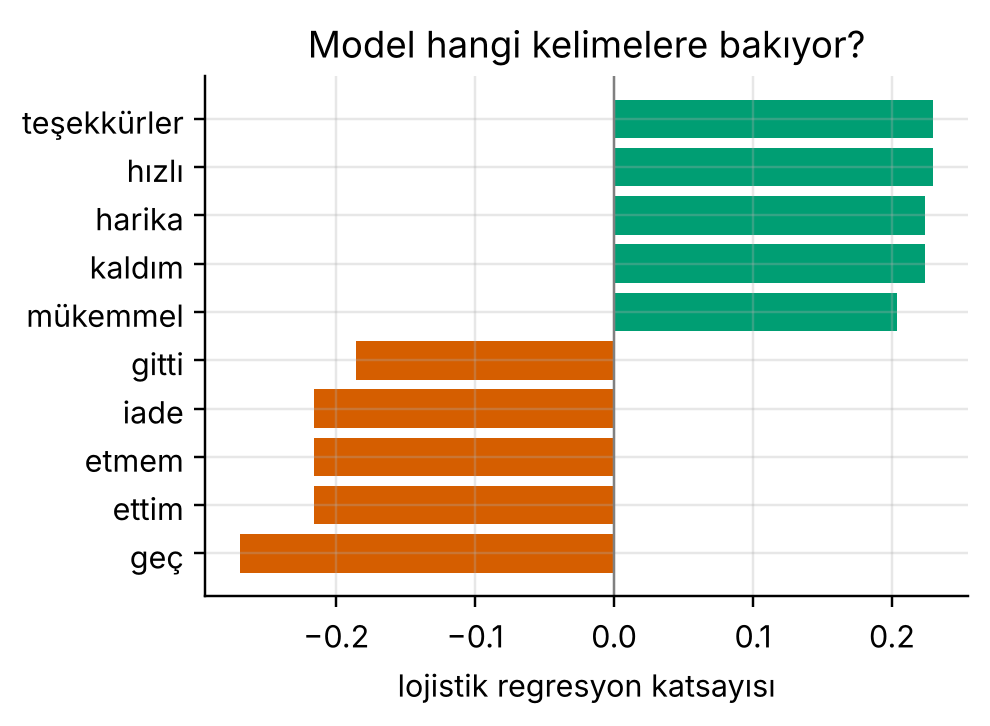

In [12]:
import numpy as np, matplotlib.pyplot as plt
tfidf, lr = model.named_steps.values()
kelime_adlari = tfidf.get_feature_names_out()
katsayi = lr.coef_[0]
sira = np.argsort(katsayi)
# en olumsuz 5 ve en olumlu 5 kelime
secim = np.r_[sira[:5], sira[-5:]]
renk = ["#D55E00"] * 5 + ["#009E73"] * 5
plt.figure(figsize=(4.6, 3.4))
plt.barh(kelime_adlari[secim], katsayi[secim], color=renk)
plt.axvline(0, color="gray", lw=0.8)
plt.xlabel("lojistik regresyon katsayısı")
plt.title("Model hangi kelimelere bakıyor?")
plt.tight_layout(); plt.show()

## 6. Kosinüs benzerliği (Çözümlü Örnek 12.3) ve kelime benzetmesi
Benzetme kısmındaki 3 boyutlu vektörler öğreticidir; gerçek gömmeler 100–300 boyutludur.

In [13]:
import numpy as np
def kosinus(u, v):
    return u @ v / (np.linalg.norm(u) * np.linalg.norm(v))

kedi  = np.array([0.8, 0.6, 0.1])          # Çözümlü Örnek 12.3
kopek = np.array([0.7, 0.7, 0.2])
araba = np.array([0.1, 0.2, 0.9])
print("cos(kedi, köpek) =", round(kosinus(kedi, kopek), 3))
print("cos(kedi, araba) =", round(kosinus(kedi, araba), 3))

# öğretici vektörlerle benzetme: kral − erkek + kadın ≈ ?
g = {"kral": [0.81, 0.28, 0.12], "kraliçe": [0.74, 0.86, 0.13],
     "erkek": [0.22, 0.24, 0.06], "kadın": [0.18, 0.79, 0.09],
     "elma": [0.10, 0.15, 0.92], "araba": [0.05, 0.20, 0.70]}
g = {k: np.array(v) for k, v in g.items()}
hedef = g["kral"] - g["erkek"] + g["kadın"]
for k in ["kraliçe", "kral", "elma", "araba"]:
    print(f"cos(hedef, {k:7s}) = {kosinus(hedef, g[k]):.3f}")

cos(kedi, köpek) = 0.985
cos(kedi, araba) = 0.311
cos(hedef, kraliçe) = 0.999
cos(hedef, kral   ) = 0.884
cos(hedef, elma   ) = 0.317
cos(hedef, araba  ) = 0.371


## Proje 2 · Skip-gram ile kendi kelime gömmelerimizi eğitmek
Her kelime çevresindeki ±2 kelimeyi tahmin etmeye çalışır. Önce (merkez, bağlam) çiftlerini çıkaralım.

In [14]:
import torch
from torch import nn
torch.manual_seed(0)
sozluk = [k for k, s in sayim.most_common() if s >= 4]  # ≥ 4 kez
kimlik = {k: i for i, k in enumerate(sozluk)}
dizi = [kimlik[k] for k in kelimeler if k in kimlik]
ciftler = []
for i, m in enumerate(dizi):                 # her merkez kelime
    for j in range(i - 2, i + 3):            # ±2 pencere
        if j != i and 0 <= j < len(dizi):
            ciftler.append((m, dizi[j]))
ciftler = torch.tensor(ciftler)
print(len(sozluk), "kelimelik sözlük |", len(ciftler), "çift")
ilk = ciftler[:3].tolist()
print("ilk çiftler:", [(sozluk[a], sozluk[b]) for a, b in ilk])

243 kelimelik sözlük | 8754 çift
ilk çiftler: [('bu', 'değil'), ('bu', 'bir'), ('değil', 'bu')]


### Negatif örneklemeyle eğitim
Gerçek çiftin skorunu büyüt, rastgele seçilen K = 5 “sahte” bağlamınkini küçült.

In [15]:
d, K = 50, 5                                         # vektör boyutu, negatif sayısı
merkez = nn.Embedding(len(sozluk), d)                # v: kelime vektörleri
baglam = nn.Embedding(len(sozluk), d)                # u: bağlam vektörleri
nn.init.uniform_(merkez.weight, -0.5 / d, 0.5 / d); nn.init.zeros_(baglam.weight)
siklik = torch.tensor([sayim[k] for k in sozluk], dtype=torch.float) ** 0.75
opt = torch.optim.Adam([*merkez.parameters(), *baglam.parameters()], lr=0.01)
for epok in range(1, 16):
    top = 0.0
    for parca in torch.randperm(len(ciftler)).split(512):
        m, b = ciftler[parca].T
        neg = torch.multinomial(siklik, len(m) * K, replacement=True).view(-1, K)
        v = merkez(m)
        poz = nn.functional.logsigmoid((v * baglam(b)).sum(-1))
        ng = nn.functional.logsigmoid(-(baglam(neg) @ v.unsqueeze(-1)).squeeze(-1))
        kayip = -(poz + ng.sum(-1)).mean()
        opt.zero_grad(); kayip.backward(); opt.step()
        top += kayip.item() * len(m)
    if epok in (1, 5, 10, 15): print(f"epok {epok:2d} | kayıp {top / len(ciftler):.3f}")

epok  1 | kayıp 3.870


epok  5 | kayıp 2.660


epok 10 | kayıp 2.354


epok 15 | kayıp 2.022


### En yakın komşular: model hangi kelimeleri benzer buldu?

In [16]:
W = merkez.weight.detach()
W = W / W.norm(dim=1, keepdim=True)        # birim vektörler
def komsular(k, n=4):
    benzerlik = W @ W[kimlik[k]]           # kosinüs benzerliği
    en_iyi = benzerlik.argsort(descending=True)[1:n + 1]
    return ", ".join(f"{sozluk[i]} {benzerlik[i]:.2f}"
                     for i in en_iyi)

for k in ["katman", "eğitim", "kelime", "ağ", "gradyan"]:
    print(f"{k:8s} → {komsular(k)}")

katman   → gizli 0.72, girdi 0.72, katmanı 0.70, ağ 0.65
eğitim   → eğitilir 0.68, test 0.68, ağırlıkları 0.67, kümesi 0.66
kelime   → temsil 0.73, spam 0.71, örneğin 0.64, metin 0.63
ağ       → katman 0.65, alt 0.54, elde 0.53, bu 0.52
gradyan  → iniş 0.62, adımda 0.61, kayıp 0.58, adım 0.58


## 7. Bigram dil modeli (Çözümlü Örnek 12.4)

In [17]:
from collections import Counter
cumleler = [["<s>", "kedi", "süt", "içer", "</s>"],
            ["<s>", "kedi", "fare", "yakalar", "</s>"],
            ["<s>", "köpek", "süt", "içer", "</s>"]]
ikili = Counter((a, b) for c in cumleler for a, b in zip(c, c[1:]))
tekli = Counter(a for c in cumleler for a in c[:-1])

def olasilik(cumle):
    p = 1.0
    for a, b in zip(cumle, cumle[1:]):
        p *= ikili[(a, b)] / tekli[a]
    return p

c1 = ["<s>", "kedi", "süt", "içer", "</s>"]
p = olasilik(c1)                          # N = 4 tahmin edilen token
print("P  =", round(p, 4), "| PP =", round(p ** (-1 / 4), 2))
c2 = ["<s>", "köpek", "fare", "yakalar", "</s>"]
print("P(köpek fare yakalar) =", olasilik(c2))

P  = 0.3333 | PP = 1.32
P(köpek fare yakalar) = 0.0


### Sıfır sayım sorunu ve Laplace (artı-bir) düzeltmesi

In [18]:
V = len({t for c in cumleler for t in c[1:]})   # </s> dahil 7 token

def laplace(cumle):
    p = 1.0
    for a, b in zip(cumle, cumle[1:]):
        p *= (ikili[(a, b)] + 1) / (tekli[a] + V)
    return p

print("V =", V)
print("P_Laplace(köpek fare yakalar) =", round(laplace(c2), 5))

V = 7
P_Laplace(köpek fare yakalar) = 0.00156


## Proje 1 · Karakter düzeyinde n-gram metin üretici
Dil modeli bir tahmin oyunudur: önceki (n − 1) harfe bakıp sonraki harfi tahmin et. Önce sayalım.

In [19]:
from collections import Counter, defaultdict
import math, random
bolme = int(len(DERLEM) * 0.9)        # %90 eğitim / %10 test
egitim, test = DERLEM[:bolme], DERLEM[bolme:]
harfler = sorted(set(DERLEM))

def ngram_say(metin, n):
    """bağlam (n−1 harf) → sonraki harf → kaç kez"""
    tablo = defaultdict(Counter)
    for i in range(n - 1, len(metin)):
        tablo[metin[i - n + 1:i]][metin[i]] += 1
    return tablo

modeller = {n: ngram_say(egitim, n) for n in range(1, 6)}
for n, m in modeller.items():
    print(f"n = {n}: {len(m):6,d} farklı bağlam")
print("“ğren” →", modeller[5]["ğren"].most_common(3))

n = 1:      1 farklı bağlam
n = 2:     87 farklı bağlam
n = 3:  1,233 farklı bağlam
n = 4:  4,946 farklı bağlam
n = 5: 11,102 farklı bağlam
“ğren” → [('m', 40), ('i', 9), ('e', 2)]


### Metin üretmek: olasılığa göre bir harf seç, ekle, tekrarla

In [20]:
def uret(n, bas="Yapay", uzunluk=68, tohum=3):
    rng, metin = random.Random(tohum), bas
    for _ in range(uzunluk):
        dagilim = modeller[n].get(metin[len(metin) - n + 1:])  # son n−1 harf
        if not dagilim:                                       # bağlam hiç görülmedi
            metin += rng.choice(harfler); continue
        adaylar, sayilar = zip(*dagilim.items())
        metin += rng.choices(adaylar, weights=sayilar)[0]     # olasılığa göre seç
    return metin.replace("\n", " ")

for n in range(1, 6):
    print(f"n={n}: {uret(n)}")

n=1: Yapayeatmı uneeNiniıdıvalo lmr vilçlhkniöç  e:iıratsmmyoön"odv yalenar n0
n=2: Yapaya çoleremain, k koo kitirminikaşesi, alea k saksim tücillçı ilgr. (0
n=3: Yapayıcılık ayığım de olduru neğitmatler, karyanınızdatmasyorişiğintümlid
n=4: Yapay sindekte ise birini sını 1 üre adınlı bölgelerini NCHW sıranı soruy
n=5: Yapay zekâ problemlerine doğru tablon keskinleri kuralığa yaygın oranı" (


### Hangi n en iyi? Eğitim ve test karmaşıklığı
Artı-k düzeltmesiyle (k = 0.01) her harfin olasılığını hesaplayıp karmaşıklığı (PP) ölçüyoruz.

eğitim PP: [25.4, 12.3, 6.5, 3.5, 2.4]
test   PP: [26.1, 14.0, 10.9, 10.3, 13.8]


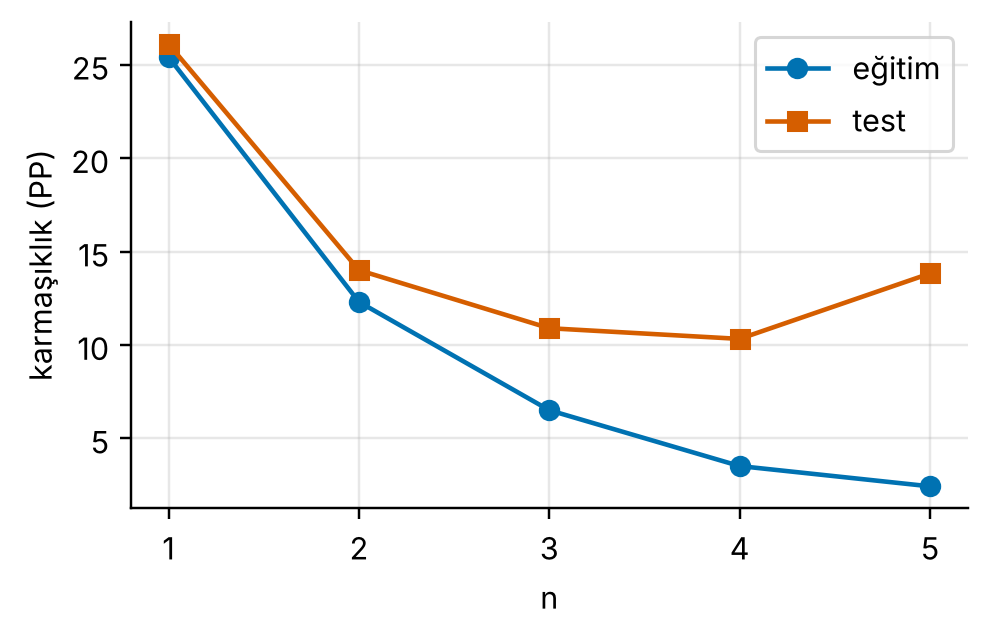

In [21]:
def karmasiklik(n, metin, k=0.01):
    m, L, V = modeller[n], 0.0, len(harfler)
    for i in range(n - 1, len(metin)):
        say = m.get(metin[i - n + 1:i], {})
        pay = say.get(metin[i], 0) + k          # artı-k düzeltmesi
        L -= math.log(pay / (sum(say.values()) + k * V))
    return math.exp(L / (len(metin) - n + 1))   # PP = e^L̄

ns = range(1, 6)
pp_egit = [karmasiklik(n, egitim[:4000]) for n in ns]
pp_test = [karmasiklik(n, test) for n in ns]
print("eğitim PP:", [round(p, 1) for p in pp_egit])
print("test   PP:", [round(p, 1) for p in pp_test])
plt.figure(figsize=(4.6, 3.0))
plt.plot(ns, pp_egit, "o-", label="eğitim")
plt.plot(ns, pp_test, "s-", label="test")
plt.xlabel("n"); plt.xticks(ns); plt.legend()
plt.ylabel("karmaşıklık (PP)"); plt.tight_layout(); plt.show()

## 8. Skaler bir RNN'de gizli durum (Çözümlü Örnek 12.5)

In [22]:
import numpy as np
h = 0.0                                   # h0
for t, x in enumerate([1, 0.5, -1], start=1):
    h = np.tanh(0.5 * h + 1.0 * x)       # yeni gizli durum
    print(f"h{t} = {h:.3f}")

h1 = 0.762
h2 = 0.707
h3 = -0.569


### RNN, GRU ve LSTM katmanlarının parametre sayısı (PyTorch)

In [23]:
import torch
from torch import nn
katmanlar = {"RNN": nn.RNN(50, 100), "GRU": nn.GRU(50, 100),
             "LSTM": nn.LSTM(50, 100)}
for ad, k in katmanlar.items():
    n = sum(p.numel() for p in k.parameters())
    print(f"{ad:4s} (girdi 50, gizli 100): {n:6d}")
print("Notlar: RNN", 100*150 + 100, "| LSTM", 4 * (100*150 + 100))

RNN  (girdi 50, gizli 100):  15200
GRU  (girdi 50, gizli 100):  45600
LSTM (girdi 50, gizli 100):  60800
Notlar: RNN 15100 | LSTM 60400


## Proje 3 · Karakter düzeyinde LSTM dil modeli
n-gram yalnızca sayar; LSTM ise harfleri vektörlere çevirir ve bir bellek (gizli durum) taşır.

In [24]:
torch.manual_seed(0)
stoi = {h: i for i, h in enumerate(harfler)}   # harf → sayı
veri = torch.tensor([stoi[h] for h in DERLEM])
egit_v, test_v = veri[:bolme], veri[bolme:]

class KarakterLSTM(nn.Module):
    def __init__(self, V, d=32, gizli=128):
        super().__init__()
        self.gomme = nn.Embedding(V, d)        # harf → vektör
        self.lstm = nn.LSTM(d, gizli, batch_first=True)  # bellek
        self.cikis = nn.Linear(gizli, V)       # harf skorları
    def forward(self, x, durum=None):
        y, durum = self.lstm(self.gomme(x), durum)
        return self.cikis(y), durum

model = KarakterLSTM(len(harfler))
n_par = sum(p.numel() for p in model.parameters())
print("parametre sayısı:", n_par)

parametre sayısı: 96951


### Örnekleme fonksiyonu: sıcaklık (T) ile bir sonraki harfi seçmek

In [25]:
@torch.no_grad()
def lstm_uret(bas="Yapay zekâ ", n=80, sicaklik=1.0, tohum=0):
    g = torch.Generator().manual_seed(tohum)
    model.eval()
    x = torch.tensor([[stoi[h] for h in bas]])
    cikti, durum = model(x)                  # başlangıcı oku
    metin = bas
    for _ in range(n):
        z = cikti[0, -1] / sicaklik          # T ile ölçekle
        p = torch.softmax(z, dim=-1)
        i = torch.multinomial(p, 1, generator=g).item()
        metin += harfler[i]                  # seçilen harfi ekle
        cikti, durum = model(torch.tensor([[i]]), durum)
    model.train()
    return metin.replace("\n", " ")

### Eğitimden önce model ne üretiyor?

In [26]:
print("Eğitimden önce:\n" + lstm_uret(n=50))

Eğitimden önce:
Yapay zekâ jüÜYE s7%DNÇIAbGşMLO;MJngP060JLİtaXU2FntJ;aq3FşwA0


### Eğitim için yardımcılar: rastgele parçalar ve test kaybı

In [27]:
def yigin(v, T=64, B=32):                          # 32 rastgele parça, 64 harf
    i = torch.randint(len(v) - T - 1, (B,))
    x = torch.stack([v[j:j + T] for j in i])
    y = torch.stack([v[j + 1:j + T + 1] for j in i])  # hedef: bir sağa kaymış metin
    return x, y

@torch.no_grad()
def test_kaybi():
    model.eval()
    cikti, _ = model(test_v[:-1].unsqueeze(0))
    model.train()
    return nn.functional.cross_entropy(cikti[0], test_v[1:]).item()

### Eğitim döngüsü (CPU'da yaklaşık yarım dakika)

In [28]:
opt = torch.optim.Adam(model.parameters(), lr=4e-3)
gecmis, en_iyi = [], (99.0, None)
for adim in range(1, 1201):
    x, y = yigin(egit_v)
    cikti, _ = model(x)                                   # her konumda tahmin
    kayip = nn.functional.cross_entropy(cikti.reshape(-1, len(harfler)), y.reshape(-1))
    opt.zero_grad(); kayip.backward()
    nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
    if adim % 50 == 0:
        t = test_kaybi(); gecmis.append((adim, kayip.item(), t))
        if t < en_iyi[0]:                                 # en iyi modeli sakla
            en_iyi = (t, {k: v.clone() for k, v in model.state_dict().items()})
        if adim % 300 == 0:
            print(f"adım {adim:4d} | eğitim {kayip.item():.2f} | test {t:.2f}")
model.load_state_dict(en_iyi[1])                         # erken durdurma
print(f"en iyi test kaybı {en_iyi[0]:.2f} → PP {math.exp(en_iyi[0]):.2f}")

adım  300 | eğitim 1.84 | test 2.09


adım  600 | eğitim 1.48 | test 1.99


adım  900 | eğitim 1.20 | test 2.04


adım 1200 | eğitim 1.09 | test 2.13
en iyi test kaybı 1.97 → PP 7.17


### Kayıp eğrisi: aşırı öğrenme nerede başlıyor?

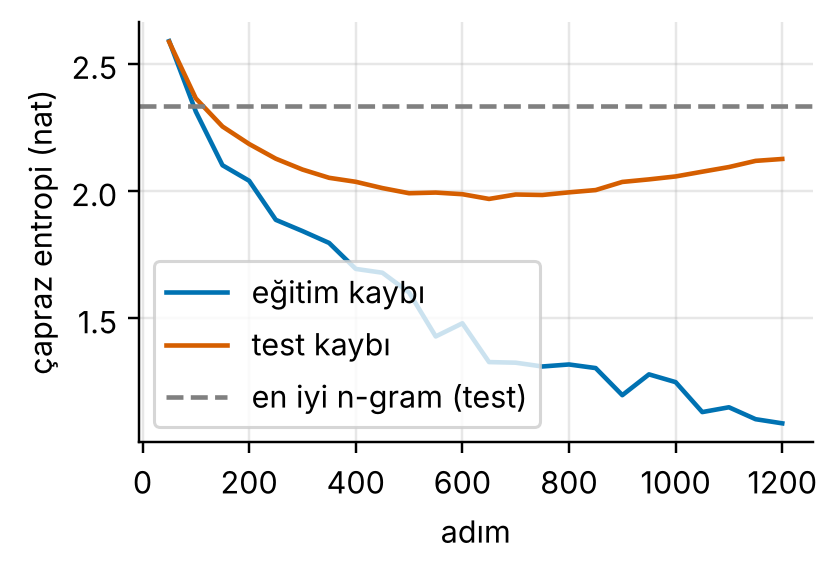

In [29]:
a, e, t = zip(*gecmis)
plt.figure(figsize=(4.0, 2.7))
plt.plot(a, e, label="eğitim kaybı")
plt.plot(a, t, label="test kaybı")
ngram = math.log(min(pp_test))         # kayıp = ln PP
plt.axhline(ngram, ls="--", c="gray",
            label="en iyi n-gram (test)")
plt.xlabel("adım"); plt.ylabel("çapraz entropi (nat)")
plt.legend(); plt.tight_layout(); plt.show()

### Sıcaklıkla üretim: düşük T temkinli, yüksek T yaratıcı (ve hatalı)

In [30]:
for T in [0.5, 1.0, 1.5]:
    print(f"T={T}: {lstm_uret(n=68, sicaklik=T)}")

T=0.5: Yapay zekâ küçük sayısını öznitelikleri karşanın başlatması (maretresini taram 
T=1.0: Yapay zekâ mürev sayıplı bir önreden değitifli 2.2 APan) söyomak e-if kavriki e


T=1.5: Yapay zekâ mürev sayıplı bişum sağılır. MLİtasyektayan alşılmaak f-de kavrikic 


### Alıştırma (Değerlendirme Soruları 8–12)
Önce elle çözün, sonra çalıştırıp karşılaştırın.

In [ ]:
print("S8 : elma/meyve(d1) =", round(1/3 * np.log(3/2), 3), "| ağacı(d3) =", round(1/2 * np.log(3), 3))
print("S9 :", round(olasilik(["<s>", "kedi", "fare", "yakalar", "</s>"]), 3))
h1 = np.tanh(1 * 0 + 0.5 * 2); h2 = np.tanh(1 * h1 + 0.5 * (-2))
print("S10: h1 =", round(h1, 3), "| h2 =", round(h2, 3))
p = np.array([0.5, 0.25, 0.1, 0.2]); L = -np.log(p).mean()
print("S11: P =", round(p.prod(), 4), "| PP =", round(p.prod() ** (-1/4), 2),
      "| L =", round(L, 3), "| e^L =", round(np.exp(L), 2), "| e^1 =", round(np.exp(1.0), 2))
print("S12: RNN =", 100 * 150 + 100, "| LSTM =", 4 * (100 * 150 + 100))